##Libraries

In [1]:
# Import general utilities
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
# from google.colab import drive

# Import TDA utilities
import gudhi
import gudhi
import gudhi.representations
from ripser import Rips
from persim.landscapes import PersLandscapeExact
from persim.landscapes import plot_landscape_simple
from persim.landscapes import PersistenceLandscaper
from persim import plot_diagrams
from tadasets import torus, sphere

# Import Scikit-Learn tools
from sklearn.decomposition import PCA
from sklearn import svm
from sklearn import metrics
from sklearn.model_selection import train_test_split
from mpl_toolkits.mplot3d import Axes3D # Required for 3D plots


##Handwriten Sample - Cher

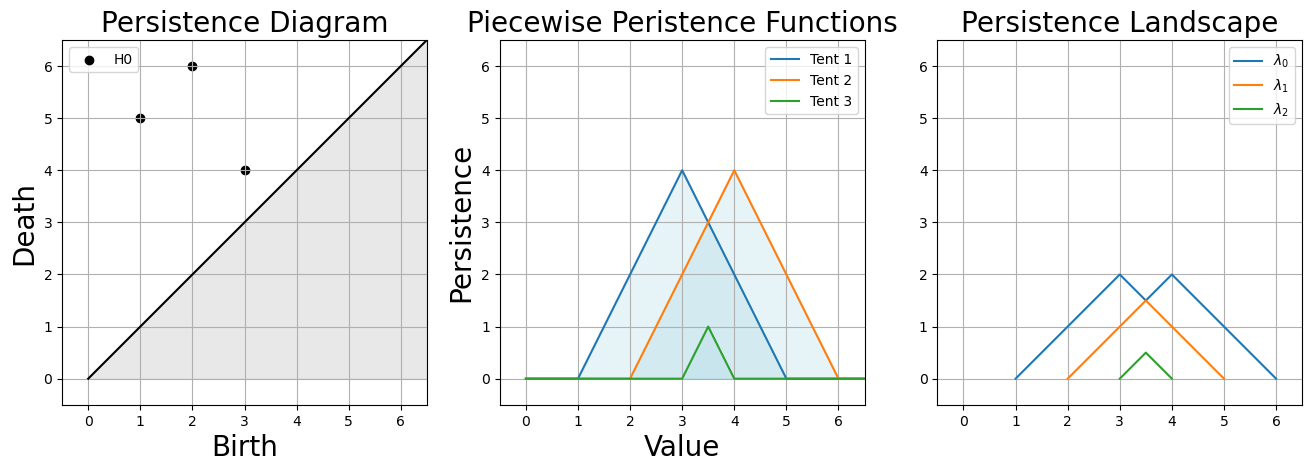

In [2]:
from scipy.spatial import transform
# Example handwritten by Cher.
sample_diagram = [
    np.array([[1,5], [2,6], [3,4]])
]
# Plotting objects
fig, axs = plt.subplots(1, 3)
fig.set_size_inches(16, 8)
# TDA Creating Persistence Landscape
landscape = PersLandscapeExact(dgms = sample_diagram, hom_deg=0)

# Plotting Peristence Diagram
axs[0].scatter([t[0] for t in sample_diagram[0]], [t[1] for t in sample_diagram[0]], label="H0", color="black")
diagonal_line_x = np.linspace(0, 6.5, 100)
axs[0].plot(diagonal_line_x, diagonal_line_x, color='black')
# Fill the area below the diagonal line in grey
axs[0].fill_between(diagonal_line_x, 0, diagonal_line_x, color='lightgray', alpha=0.5)
axs[0].set_title("Persistence Diagram", fontsize=20)
axs[0].set_xlabel("Birth", fontsize=20)
axs[0].set_ylabel("Death", fontsize=20)
axs[0].set_xlim([0, 6.5])
axs[0].set_ylim([0, 6.5])
axs[0].legend(fontsize=20, title="Dimension", loc='lower right') # Increased fontsize to 20

# Plotting Piecewise Peristence Functions
axs[1].set_title("Piecewise Peristence Functions", fontsize=20)
axs[1].set_xlabel("Value", fontsize=20)
axs[1].set_ylabel("Persistence", fontsize=20)
axs[1].set_xlim([-.5, 6.5])
axs[1].set_ylim([-.5, 6.5])

midpt = lambda birth, death: (birth + death) / 2
lifespan = lambda birth, death: death - birth

# Correctly generate x and y coordinates for each tent function
all_l_x = []
all_l_y = []

for i in range(len(sample_diagram[0])):
    b, d = sample_diagram[0][i]
    mid_point = midpt(b, d)
    life_span = lifespan(b, d)

    # Coordinates for one tent function, extended to the plotting limits if necessary
    # This matches the (birth,0) -> (midpoint, lifespan) -> (death,0) pattern.
    x_tent = [0, b, mid_point, d, 6.6] # Extend to 0 and 6.6 for full range visibility
    y_tent = [0, 0, life_span, 0, 0]

    all_l_x.append(x_tent)
    all_l_y.append(y_tent)

for i in range(len(all_l_x)):
  axs[1].plot(all_l_x[i], all_l_y[i], label=f"Tent {i+1}")
  axs[1].fill_between(all_l_x[i], 0, all_l_y[i], color='lightblue', alpha=0.3)

# Plot Persistence Landscape
axs[2].set_title("Persistence Landscape", fontsize=20)
plot_landscape_simple(
    landscape,
    ax=axs[2],
)


for i in range(0,3):
  axs[i].grid(True)
  axs[i].set_aspect('equal', adjustable='box')
  axs[i].set_xlim([-.5, 6.5])
  axs[i].set_ylim([-.5, 6.5])
  axs[i].legend(fontsize=10) # Increased fontsize to 20

##Creating Sample Data: Circle, 1D double Tourus, Torus, and Sphere

In [3]:
num_points = 100
radius = 1
noise_level = .5

theta = np.linspace(0, 2 * np.pi, num_points)
x_perfect = radius * np.cos(theta)
y_perfect = radius * np.sin(theta)

x_noise = np.random.uniform(-noise_level, noise_level, num_points)
y_noise = np.random.uniform(-noise_level, noise_level, num_points)

x_approx = x_perfect + x_noise
y_approx = y_perfect + y_noise

Circular_data = np.column_stack((x_approx, y_approx))


# Creating Double Torus 2D datacloud points.
num_points_eight = 100
noise_level_eight = 0.1 # Small noise to make it realistic

t = np.linspace(-np.pi, np.pi, num_points_eight)
x_eight = 2*(np.sin(t))
y_eight = 2*(np.cos(t)) * (np.sin(t))


x_noise_eight = np.random.normal(0, noise_level_eight, num_points_eight)
y_noise_eight = np.random.normal(0, noise_level_eight, num_points_eight)

DoubleTorus2D_data = np.column_stack((x_eight + x_noise_eight, y_eight + y_noise_eight))

# Creating Sphere datacloud points with noise.
num_points_sphere = 100
radius_sphere = 3
noise_level_sphere = .1
Sphere_data = sphere(n=num_points_sphere, r=radius_sphere, noise=noise_level_sphere)


# Creating 3D Torus datacloud points with noice.
num_points_torus = 100
c_torus = 1 # Major axis
a_torus = 1 # Minor axis

noise_level_torus = 0.1 # Small noise to make it realistic but retain shape

Torus_data = torus(n=num_points_torus, c=c_torus, a=a_torus, noise=noise_level_torus)


##Visualizing the Data

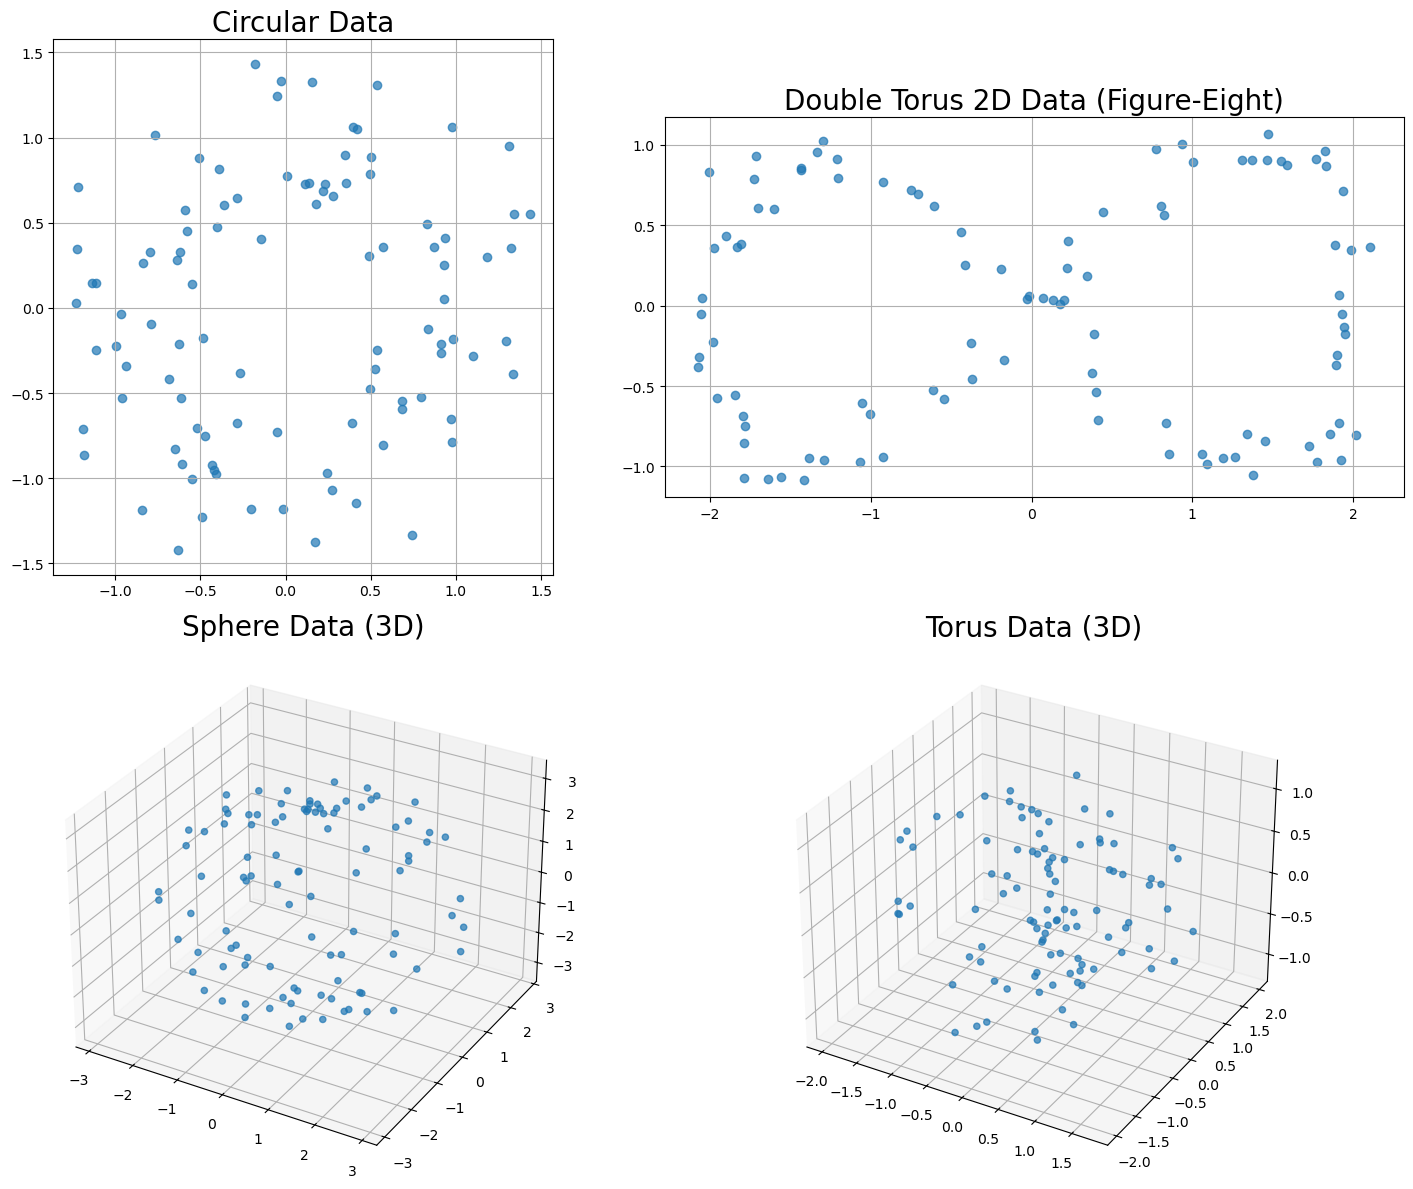

In [4]:

fig = plt.figure(figsize=(15, 12))

# Subplot 1: Circular Data (2D)
ax1 = fig.add_subplot(2, 2, 1)
ax1.scatter(Circular_data[:, 0], Circular_data[:, 1], alpha=0.7)
ax1.set_title("Circular Data", fontsize=20) # Increased fontsize to 20

ax1.set_aspect('equal', adjustable='box')
ax1.grid(True)

# Subplot 2: Double Torus 2D Data (Figure-Eight)
ax2 = fig.add_subplot(2, 2, 2)
ax2.scatter(DoubleTorus2D_data[:, 0], DoubleTorus2D_data[:, 1], alpha=0.7)
ax2.set_title("Double Torus 2D Data (Figure-Eight)", fontsize=20) # Increased fontsize to 20
ax2.set_aspect('equal', adjustable='box')
ax2.grid(True)

# Subplot 3: Sphere Data (3D)
ax3 = fig.add_subplot(2, 2, 3, projection='3d')
ax3.scatter(Sphere_data[:, 0], Sphere_data[:, 1], Sphere_data[:, 2], alpha=0.7)
ax3.set_title("Sphere Data (3D)", fontsize=20) # Increased fontsize to 20

# Subplot 4: Torus Data (3D)
ax4 = fig.add_subplot(2, 2, 4, projection='3d')
ax4.scatter(Torus_data[:, 0], Torus_data[:, 1], Torus_data[:, 2], alpha=0.7)
ax4.set_title("Torus Data (3D)", fontsize=20) # Increased fontsize to 20


plt.tight_layout()
plt.show()

##TDA Analysis:

###Creating Persistance Landscapes

In [7]:
dmg_Circular_data      = Rips(maxdim=3).fit_transform(Circular_data)
dmg_DoubleTorus2D_data = Rips(maxdim=3).fit_transform(DoubleTorus2D_data)
dmg_Sphere_data        = Rips(maxdim=3).fit_transform(Sphere_data)
dmg_Torus_data         = Rips(maxdim=3).fit_transform(Torus_data)

Rips(maxdim=3, thresh=inf, coeff=2, do_cocycles=False, n_perm = None, verbose=True)
Rips(maxdim=3, thresh=inf, coeff=2, do_cocycles=False, n_perm = None, verbose=True)
Rips(maxdim=3, thresh=inf, coeff=2, do_cocycles=False, n_perm = None, verbose=True)
Rips(maxdim=3, thresh=inf, coeff=2, do_cocycles=False, n_perm = None, verbose=True)


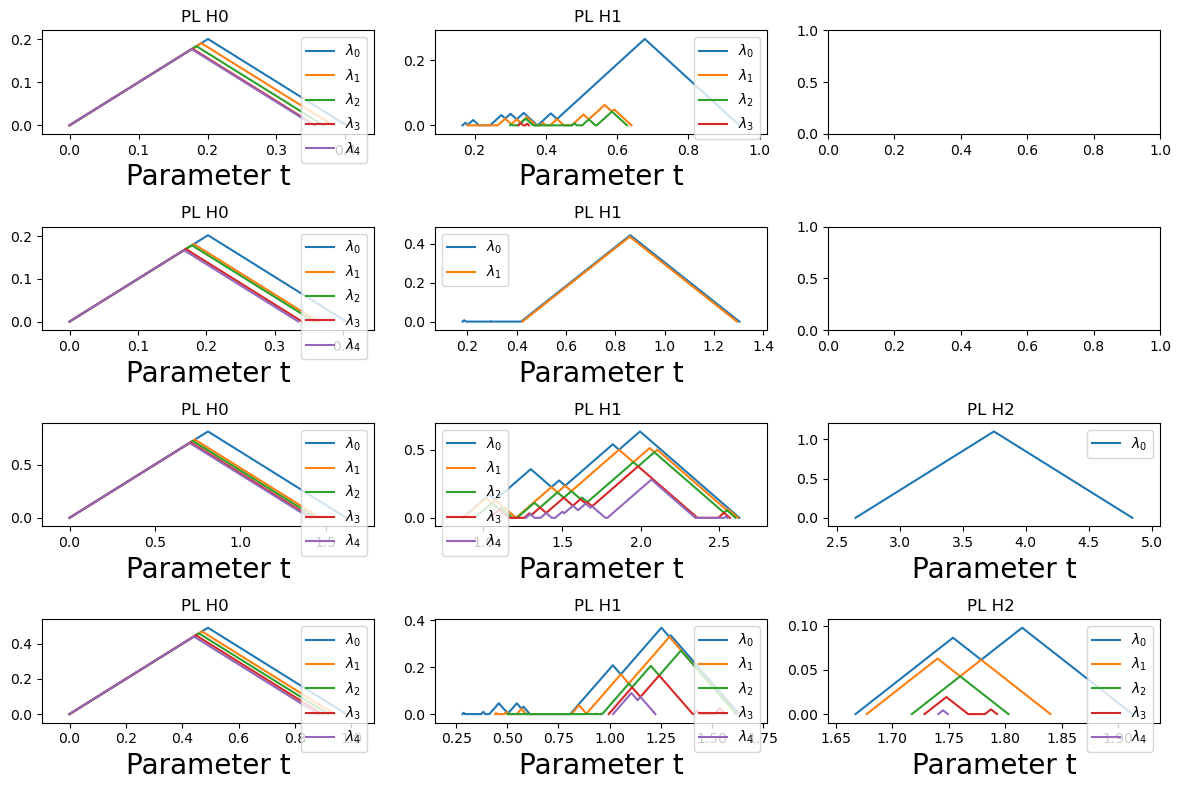

In [11]:



fig, axs = plt.subplots(4, 3) # 4 Persistence Landscape and three properties ( H0 - H2)
fig.set_size_inches(12, 8)

ax = axs.flatten()

for i in range(0,2):
  plot_landscape_simple(
      PersLandscapeExact(dmg_Circular_data, hom_deg=i),
      title = f"PL H{i%3} ",
      ax=ax[i], depth_range = range(5))
  ax[i].set_xlabel("Parameter t", fontsize=20)
  # ax[i].set_ylabel("LV", fontsize=20)
for i in range(3,5):
  plot_landscape_simple(
    PersLandscapeExact(dmg_DoubleTorus2D_data, hom_deg=i%3),
    title = f"PL H{i%3} ",
    ax=ax[i], depth_range = range(5))
  ax[i].set_xlabel("Parameter t", fontsize=20)
  # ax[i].set_ylabel("LV  ", fontsize=20)

for i in range(6,9):
  plot_landscape_simple(
    PersLandscapeExact(dmg_Sphere_data, hom_deg=i%3),
    title = f"PL H{i%3} ",
    ax=ax[i], depth_range = range(5
                                  ))
  ax[i].set_xlabel("Parameter t", fontsize=20)
  # ax[i].set_ylabel("LV", fontsize=20)
for i in range(9,12):
  plot_landscape_simple(
    PersLandscapeExact(dmg_Torus_data, hom_deg=i%3),
    title = f"PL H{i%3} ",
    ax=ax[i], depth_range = range(5))
  ax[i].set_xlabel("Parameter t", fontsize=20)
  # ax[i].set_ylabel("LV", fontsize=20)
fig.tight_layout()
